# Rutas en Medellín según la hora del día

**Fundamentos de IA** · Proyecto de búsqueda de rutas

---

La idea es sencilla: una misma ruta no es igual de buena a las 8 de la mañana que a las 11 de la
noche. Este notebook construye el mapa de calles de Medellín, le pega a cada calle
**qué tan insegura es en cada franja del día**, y luego busca rutas con los algoritmos
de búsqueda vistos en clase.

### Qué se usa de cada archivo

| Archivo | Para qué |
|---|---|
| `hurto_a_persona.csv`, `hurto_de_moto.csv`, `hurto_de_carro.csv`, `hurto_por_pirateria_terrestre.csv` | Contar robos cerca de cada calle, separados por franja horaria |
| `202608091356-ansv-fotodeteccion.csv` | Marcar qué calles tienen cámara (solo Medellín) |
| `velocidad_e_intensidad_vehicular_en_medellin.csv` | Velocidad real de los corredores principales |

### Decisiones de diseño

1. **Todo en metros, nada en grados.** El mapa se proyecta a coordenadas planas, así que
   las distancias son euclidianas de toda la vida: `√((x₂-x₁)² + (y₂-y₁)²)`.
2. **Dos tablas.** Los nodos van a un DataFrame y las aristas a otro. Toda la información
   se le agrega a la tabla de aristas, que es la que manda.
3. **Un peso simple y explicable.** Nada de fórmulas con cinco parámetros: la calle insegura
   simplemente "se siente más larga".
4. **Algoritmos escritos a mano.** Costo uniforme, primero el mejor y A\*, sin llamar a
   `networkx.shortest_path`.

## 0. Instalación

In [1]:
# ======================================================================
# Instala lo que falte y verifica que esté todo. Se puede volver a correr.
# ======================================================================
# Aviso importante: osmnx decide si puede dibujar mapas EN EL MOMENTO en que
# se importa. Si lo importas antes de que matplotlib exista, se queda sin
# dibujo el resto de la sesión. Si esta celda te dice que reinicies, reinicia.

import importlib, subprocess, sys

PAQUETES = {
    "numpy": "numpy", "pandas": "pandas", "networkx": "networkx",
    "scipy": "scipy", "osmnx": "osmnx", "geopandas": "geopandas",
    "shapely": "shapely", "pyproj": "pyproj", "geopy": "geopy",
    "requests": "requests", "matplotlib": "matplotlib", "folium": "folium",
}

faltan = [pip for pip, imp in PAQUETES.items() if importlib.util.find_spec(imp) is None]
if faltan:
    print("Instalando:", ", ".join(faltan))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan])
    importlib.invalidate_caches()
else:
    print("Todo instalado.")

if "osmnx" in sys.modules:
    from osmnx import plot as _p
    if not getattr(_p, "mpl_available", True):
        print("\n*** REINICIA EL KERNEL Y VUELVE A EJECUTAR ***")

Todo instalado.


In [2]:
import re, unicodedata, heapq, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import osmnx as ox
import folium
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree      # búsqueda de vecinos en coordenadas planas
from pyproj import Transformer

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (11, 5)

print("osmnx", ox.__version__)

osmnx 2.1.1


## 1. Configuración

Aquí está todo lo que se puede tocar sin meterse en el código.

In [3]:
CARPETA_DATOS = Path("datos")
CARPETA_CACHE = Path("cache");   CARPETA_CACHE.mkdir(exist_ok=True)
CARPETA_SALIDA = Path("salidas"); CARPETA_SALIDA.mkdir(exist_ok=True)

CIUDAD = "Medellín, Antioquia, Colombia"

# ----------------------------------------------------------------------
# SISTEMAS DE COORDENADAS
# ----------------------------------------------------------------------
# Trabajamos en dos sistemas y conviene tener claro para qué sirve cada uno:
#
#   EPSG:4326  -> grados (latitud/longitud). Es lo que entienden OSM y Folium.
#   EPSG:3116  -> metros (MAGNA-SIRGAS Bogotá). Es un PLANO. Aquí calculamos.
#
# Elegimos el 3116 porque el archivo de velocidad ya viene en ese sistema.
SISTEMA_GRADOS = "EPSG:4326"
SISTEMA_METROS = "EPSG:3116"

# ----------------------------------------------------------------------
# FRANJAS HORARIAS
# ----------------------------------------------------------------------
# (nombre, hora_inicio, hora_fin). La noche cruza la medianoche.
FRANJAS = {
    "manana": (6, 12),    # 06:00 - 11:59
    "tarde":  (12, 19),   # 12:00 - 18:59
    "noche":  (19, 6),    # 19:00 - 05:59
}

# ----------------------------------------------------------------------
# PARÁMETROS DEL ANÁLISIS
# ----------------------------------------------------------------------
ANIO_MINIMO = 2019      # solo robos recientes
RADIO_ROBOS = 300       # metros: qué tan cerca cuenta un robo para una calle
RADIO_CAMARAS = 300     # metros: alcance de una cámara
RADIO_SENSORES = 700    # metros: distancia máxima para usar un sensor de velocidad

# Caja de Medellín, para descartar coordenadas mal escritas
LAT_MIN, LAT_MAX = 6.13, 6.40
LON_MIN, LON_MAX = -75.72, -75.47

# Conversores entre los dos sistemas (se usan en varias celdas)
a_metros = Transformer.from_crs(SISTEMA_GRADOS, SISTEMA_METROS, always_xy=True)
a_grados = Transformer.from_crs(SISTEMA_METROS, SISTEMA_GRADOS, always_xy=True)

print("Franjas:", {k: f"{a:02d}:00-{b:02d}:00" for k, (a, b) in FRANJAS.items()})

Franjas: {'manana': '06:00-12:00', 'tarde': '12:00-19:00', 'noche': '19:00-06:00'}


## 2. Los robos

De la columna `fecha_hecho` sacamos **año** y **hora**, y con la hora clasificamos cada robo
en su franja. Un robo a las 21:30 cuenta para la noche y no para la mañana.

In [4]:
ARCHIVOS_ROBOS = [
    "hurto_a_persona.csv",
    "hurto_de_moto.csv",
    "hurto_de_carro.csv",
    "hurto_por_pirateria_terrestre.csv",
]

COLUMNAS = ["fecha_hecho", "latitud", "longitud", "nombre_barrio", "lugar", "modalidad"]

def clasificar_franja(hora):
    # Devuelve "manana", "tarde" o "noche" según la hora (0-23)
    if 6 <= hora < 12:
        return "manana"
    if 12 <= hora < 19:
        return "tarde"
    return "noche"          # 19:00-23:59 y 00:00-05:59

partes = []
for archivo in ARCHIVOS_ROBOS:
    t = pd.read_csv(CARPETA_DATOS / archivo, usecols=COLUMNAS, low_memory=False)
    t["tipo_robo"] = archivo.replace("hurto_", "").replace(".csv", "")
    partes.append(t)
    print(f"  {archivo:38s} {len(t):>7,} filas")

robos = pd.concat(partes, ignore_index=True)

# --- extraer año y hora de la fecha ---
# El formato es "2017-01-01T01:00:00.000-05:00", así que basta con cortar el texto:
#   posiciones 0-3   -> año
#   posiciones 11-12 -> hora
fecha = robos["fecha_hecho"].astype(str)
robos["anio"] = pd.to_numeric(fecha.str[:4], errors="coerce")
robos["hora"] = pd.to_numeric(fecha.str[11:13], errors="coerce")

print(f"\nTotal sin filtrar: {len(robos):,}")
robos.head(3)

  hurto_a_persona.csv                    326,489 filas
  hurto_de_moto.csv                       86,410 filas
  hurto_de_carro.csv                      39,571 filas
  hurto_por_pirateria_terrestre.csv        2,202 filas

Total sin filtrar: 454,672


,fecha_hecho,latitud,longitud,modalidad,nombre_barrio,lugar,tipo_robo,anio,hora
0,2017-01-01T01:00:00.000-05:00,6.299703,-75.582016,Atraco,Doce de Octubre No.2,Vía pública,a_persona,2017,1
1,2017-01-01T15:00:00.000-05:00,6.250917,-75.566160,Atraco,La Candelaria,Vía pública,a_persona,2017,15
2,2017-01-01T14:00:00.000-05:00,6.274836,-75.554909,Descuido,Campo Valdés No.1,Vía pública,a_persona,2017,14


In [5]:
# ======================================================================
# LIMPIEZA DE LOS ROBOS
# ======================================================================
antes = len(robos)

# Las coordenadas vienen como texto en algunas filas; errors="coerce"
# convierte lo que no se pueda parsear en NaN en vez de reventar.
robos["latitud"]  = pd.to_numeric(robos["latitud"],  errors="coerce")
robos["longitud"] = pd.to_numeric(robos["longitud"], errors="coerce")

# 1) Fuera las filas sin ubicación o sin fecha utilizable (~16% del total)
robos = robos.dropna(subset=["latitud", "longitud", "hora", "anio"])

# 2) Fuera las coordenadas imposibles. Hay filas con longitud -0,0007, que es
#    el meridiano de Greenwich: error de captura. La caja de Medellín las tira.
robos = robos[robos["latitud"].between(LAT_MIN, LAT_MAX)]
robos = robos[robos["longitud"].between(LON_MIN, LON_MAX)]

# 3) Solo años recientes: antes de 2019 el registro es mucho más flojo y
#    mezclarlos haría parecer seguras zonas donde solo había menos denuncias.
robos = robos[robos["anio"] >= ANIO_MINIMO]

# 4) Clasificar cada robo en su franja según la hora
robos["franja"] = robos["hora"].astype(int).apply(clasificar_franja)

# 5) Pasar de grados a METROS. A partir de aquí los robos viven en el mismo
#    plano que el grafo, y se pueden cruzar con distancias euclidianas.
#    transform espera (longitud, latitud) en ese orden, no al revés.
x, y = a_metros.transform(robos["longitud"].values, robos["latitud"].values)
robos["x"] = x
robos["y"] = y

robos = robos.reset_index(drop=True)

print(f"{antes:,} -> {len(robos):,} robos utilizables "
      f"(se descartó el {(1-len(robos)/antes)*100:.1f}%)\n")
print(robos["franja"].value_counts().to_string())
robos[["anio", "hora", "franja", "tipo_robo", "nombre_barrio", "x", "y"]].head()

454,672 -> 170,456 robos utilizables (se descartó el 62.5%)

franja
noche     74834
tarde     51150
manana    44472


,anio,hora,franja,tipo_robo,nombre_barrio,x,y
0,2020,15,tarde,a_persona,Villa Nueva,835399.627984,1.183625e+06
1,2020,6,manana,a_persona,Los Cerros el Vergel,837605.079577,1.181273e+06
2,2020,7,manana,a_persona,El Salvador,835522.553964,1.181529e+06
3,2020,11,manana,a_persona,Villa Nueva,835669.011344,1.183617e+06
4,2020,11,manana,a_persona,El Salado,829034.458907,1.183596e+06


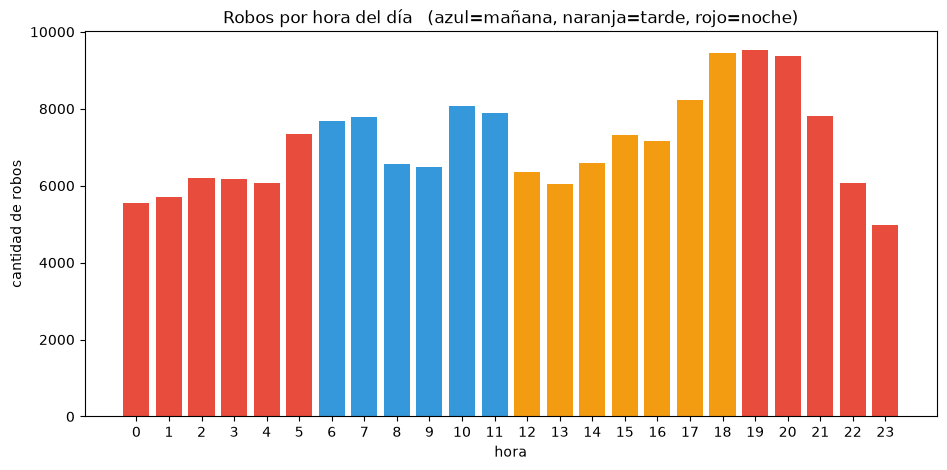

tipo_robo,a_persona,de_carro,de_moto,por_pirateria_terrestre
franja,,,,
manana,38889,928,4654,1
noche,61815,1953,11066,0
tarde,46199,898,4044,9


In [6]:
# ¿A qué hora roban más? Esto es lo que justifica separar por franjas.
conteo_hora = robos.groupby("hora").size()
colores = ["#e74c3c" if clasificar_franja(h) == "noche"
           else "#f39c12" if clasificar_franja(h) == "tarde"
           else "#3498db" for h in conteo_hora.index]

plt.bar(conteo_hora.index, conteo_hora.values, color=colores)
plt.title("Robos por hora del día   (azul=mañana, naranja=tarde, rojo=noche)")
plt.xlabel("hora"); plt.ylabel("cantidad de robos"); plt.xticks(range(0, 24))
plt.show()

resumen = robos.groupby(["franja", "tipo_robo"]).size().unstack(fill_value=0)
display(resumen)

### Decisiones sobre los archivos de hurto

| Decisión | Por qué |
|---|---|
| **Juntar los 4 archivos en una sola tabla** | Comparten exactamente el mismo esquema de columnas. A efectos de "por aquí roban", da igual si te quitaron el celular o la moto. |
| **Todos los robos pesan igual** | Se podría dar más peso al hurto a persona que al de carro, pero eso mete un parámetro más que habría que justificar. Con peso igual, el número que sale es literal: *cuántos robos hubo cerca*. |
| **Solo desde 2019** | Los datos llegan hasta 2022-2023. Antes de 2019 el registro es mucho más flojo (1.894 casos en 2011 frente a 45.502 en 2019), así que mezclarlos deformaría el mapa: parecería que había menos delito donde en realidad había menos denuncia registrada. |
| **Descartar las filas sin coordenada** | Es el **15,9 %** de los registros y no hay forma de ubicarlos. El sesgo es leve entre comunas (11 % a 27 %), pero conviene saberlo: en "Vía pública" falta el 19,2 %, y esa es justo la categoría que más importa para rutas. |
| **Filtrar por una caja de coordenadas** | Hay datos rotos: una fila tiene longitud -0,0007, o sea el meridiano de Greenwich. La caja del Valle de Aburrá descarta 74 registros de 170.000, todos basura. |
| **Franjas en vez de hora exacta** | Con 24 columnas de inseguridad el modelo sería más fino pero mucho menos explicable, y cada hora tendría menos datos. Tres franjas dejan suficientes robos en cada una para que el conteo sea estable. |

## 3. Las cámaras

Del registro nacional nos quedamos **solo con Medellín** y solo con las que están funcionando.
Una cámara vencida no sirve de nada.

In [7]:
camaras = pd.read_csv(CARPETA_DATOS / "202608091356-ansv-fotodeteccion.csv", low_memory=False)
camaras.columns = [c.strip() for c in camaras.columns]
print(f"Registro nacional completo: {len(camaras):,} cámaras")

# --- solo Medellín ---
municipio = camaras["Municipio"].astype(str).str.upper().str.strip()
camaras = camaras[municipio.isin(["MEDELLIN", "MEDELLÍN"])].copy()
print(f"Solo Medellín: {len(camaras)}")

# --- solo las que operan ---
ESTADOS_BUENOS = ["Operando", "Autorizada instalar", "Prorrogada"]
camaras = camaras[camaras["Estado operación"].isin(ESTADOS_BUENOS)]
print(f"Solo las activas: {len(camaras)}")

camaras["latitud"]  = pd.to_numeric(camaras["Latitud"],  errors="coerce")
camaras["longitud"] = pd.to_numeric(camaras["Longitud"], errors="coerce")
camaras = camaras.dropna(subset=["latitud", "longitud"])

x, y = a_metros.transform(camaras["longitud"].values, camaras["latitud"].values)
camaras["x"] = x
camaras["y"] = y
camaras = camaras.reset_index(drop=True)

print(f"\nCámaras finales: {len(camaras)}")
display(camaras["Tipo de tecnología"].value_counts())

Registro nacional completo: 1,335 cámaras
Solo Medellín: 133
Solo las activas: 51

Cámaras finales: 51


Tipo de tecnología
Radar Doppler    51
Name: count, dtype: int64

### Decisiones sobre las cámaras

| Decisión | Por qué |
|---|---|
| **Solo Medellín** | El archivo es el registro nacional (1.335 cámaras). En Antioquia hay 249 y en Medellín 133. Las de Bello o Envigado no pintan nada en un mapa que solo cubre Medellín. |
| **Solo las que operan** | Menos de la mitad están activas. Una cámara *Vencida* o *Renovada - Expirada* no disuade a nadie, así que contarla daría un bono de seguridad falso. |
| **Contar "hay o no hay", no cuántas** | Se usa `tiene_camara` (0 o 1) y no el número. Con tan pocas cámaras, contar cuántas hay cerca mete ruido sin aportar nada. |

> **Advertencia honesta que conviene poner en el informe.** Estas son cámaras de
> **fotodetección**: radar Doppler, espiras inductivas y Lidar. Detectan exceso de velocidad y
> semáforo en rojo, **no vigilan hurtos**. Que reduzcan el riesgo de atraco es una hipótesis
> nuestra, no algo que el dato respalde. Lo que sí marcan de forma fiable es *corredor arterial
> vigilado*, que empíricamente sí tiene menos atraco de oportunidad. Además son pocas, así que
> su efecto sobre la ruta es pequeño.

## 4. La velocidad real

Este archivo trae dos trampas:

1. Las columnas `longitud` y `latitud` **no son grados**: son metros en EPSG:3116.
   Como nosotros vamos a trabajar justo en ese sistema, nos las quedamos tal cual.
2. Usa **coma decimal** en vez de punto.

In [8]:
COLS_VEL = ["hora", "velocidad_km_h", "corredor", "sentido", "longitud", "latitud"]
vel = pd.read_csv(CARPETA_DATOS / "velocidad_e_intensidad_vehicular_en_medellin.csv",
                  usecols=COLS_VEL, dtype=str)

# coma decimal -> punto
for c in ["longitud", "latitud"]:
    vel[c] = vel[c].str.replace(",", ".", regex=False).astype(float)
for c in ["hora", "velocidad_km_h"]:
    vel[c] = pd.to_numeric(vel[c], errors="coerce")

# ¡Ojo! Aquí "longitud" y "latitud" ya son X e Y en metros. Solo hay que renombrar.
vel = vel.rename(columns={"longitud": "x", "latitud": "y"})
vel = vel[(vel["velocidad_km_h"] > 0) & (vel["velocidad_km_h"] < 130)]

# Un sensor = un punto (x, y). Promediamos su velocidad.
sensores = (vel.groupby(["x", "y", "corredor"], as_index=False)
               .agg(velocidad_real=("velocidad_km_h", "mean"),
                    mediciones=("velocidad_km_h", "size")))

print(f"{len(vel):,} mediciones en {len(sensores)} sensores")
sensores.head()

425,756 mediciones en 149 sensores


,x,y,corredor,velocidad_real,mediciones
0,826542.6250,1186316.75,V���a al T���nel de Occidente,37.739461,1447
1,826956.5625,1186004.00,V���a al T���nel de Occidente,16.815395,1468
2,829333.0625,1186061.00,V���a al Mar,20.619272,1484
3,830604.8750,1181859.50,Avenida 33,27.957841,2965
4,830676.1875,1183354.50,San Juan,27.525241,1763


### Decisiones sobre el archivo de velocidad

| Decisión | Por qué |
|---|---|
| **No convertir las coordenadas** | Vienen en EPSG:3116, en metros. Como todo el proyecto trabaja en ese mismo sistema, entran directo. Si alguien las tomara por grados, toda esta capa acabaría en mitad del océano. |
| **Cambiar la coma decimal por punto** | El archivo usa formato español (`833291,8125`). Sin esto, `pandas` lee las coordenadas como texto. |
| **Descartar velocidades de 0 o más de 130** | Un sensor parado marca 0 y rompe la división al calcular el tiempo. Por encima de 130 km/h en ciudad es error de medición. |
| **Promediar por punto de sensor** | Hay 431.490 mediciones repartidas en unos 130 puntos. Lo que necesitamos por calle es un número, no la serie entera. |
| **Usar el sensor más cercano si está a menos de 700 m** | Es lo más simple que funciona. Se probó cruzar por nombre de calle, pero varios corredores se llaman `Calle 52 - La Playa` o `Carrera 57 - Avenida Ferrocarril` y no coinciden literalmente con OSM. No compensa la complejidad. |

**Limitaciones que hay que reconocer:** los datos son de **93 días de julio a septiembre de
2020**, en plena pandemia, así que las velocidades están infladas respecto a un día normal. Y
los 49 corredores con sensor son todos **arterias** (Autopista Norte, Las Vegas, Oriental,
San Juan): en calles residenciales no hay ni un dato y se cae a la velocidad teórica de OSM.

### Un archivo que se decidió NO usar

`Criminalidad por Comuna_data.csv` traía la tasa de criminalidad de las 21 comunas. Se
descartó por dos razones:

1. **La tasa está calculada sobre población residente.** La Candelaria da 1.193 frente a 13 de
   Palmitas. Eso no significa que el centro sea 90 veces más peligroso: significa que tiene
   mucha gente flotante y poca censada. El indicador mide otra cosa.
2. **Es redundante.** Los propios archivos de hurto ya traen la ubicación exacta de cada caso,
   que es información más fina que un promedio por comuna.

## 5. El mapa de calles

Se descarga de OpenStreetMap y **se proyecta a metros**. Después de `project_graph`
las coordenadas `x` e `y` de cada nodo dejan de ser grados y pasan a ser metros sobre
un plano, que es justo lo que queremos: a partir de ahí toda la geometría es euclidiana.

In [9]:
ARCHIVO_GRAFO = CARPETA_CACHE / "medellin_drive.graphml"

VELOCIDADES_POR_TIPO = {
    "motorway": 80, "trunk": 70, "primary": 60, "secondary": 50,
    "tertiary": 40, "residential": 30, "living_street": 20,
    "unclassified": 30, "service": 20, "road": 30,
}

if ARCHIVO_GRAFO.exists():
    print("Cargando el mapa desde cache...")
    grafo_grados = ox.load_graphml(ARCHIVO_GRAFO)
else:
    print("Descargando el mapa de OpenStreetMap (tarda unos minutos)...")
    grafo_grados = ox.graph_from_place(CIUDAD, network_type="drive")
    grafo_grados = ox.add_edge_speeds(grafo_grados, hwy_speeds=VELOCIDADES_POR_TIPO, fallback=30)
    grafo_grados = ox.add_edge_travel_times(grafo_grados)
    ox.save_graphml(grafo_grados, ARCHIVO_GRAFO)

# Proyectar: de grados a metros. Este es el paso que vuelve todo plano.
grafo = ox.project_graph(grafo_grados, to_crs=SISTEMA_METROS)

print(f"\nNodos:   {grafo.number_of_nodes():,}")
print(f"Aristas: {grafo.number_of_edges():,}")
print(f"Sistema de coordenadas: {grafo.graph['crs']}")

Cargando el mapa desde cache...

Nodos:   18,314
Aristas: 43,284
Sistema de coordenadas: EPSG:3116


## 6. Las dos tablas

Aquí pasamos del grafo a **dos DataFrames**, que es como vamos a trabajar de aquí en adelante:

* **`nodos`** — las esquinas. Cada una con su `x`, `y` en metros y su `lat`, `lon` en grados
  (los grados solo se usan al final, para dibujar el mapa).
* **`aristas`** — los tramos de calle. Es la tabla importante: aquí le vamos a ir pegando
  columna por columna toda la información de robos, cámaras y velocidad.

Un detalle: OSM a veces tiene **varias calles entre las mismas dos esquinas** (una avenida con
calzadas separadas, por ejemplo). Para simplificar nos quedamos con la más corta de cada par.

In [10]:
# ----------------------------------------------------------------------
# TABLA DE NODOS
# ----------------------------------------------------------------------
filas = []
for id_nodo, datos in grafo.nodes(data=True):
    filas.append({
        "id_nodo": id_nodo,
        "x": datos["x"],                          # metros
        "y": datos["y"],                          # metros
        "lat": grafo_grados.nodes[id_nodo]["y"],  # grados, solo para dibujar
        "lon": grafo_grados.nodes[id_nodo]["x"],
    })
nodos = pd.DataFrame(filas)

print(f"{len(nodos):,} nodos")
display(nodos.head())

18,314 nodos


,id_nodo,x,y,lat,lon
0,309026271,834490.710023,1.178862e+06,6.211516,-75.572858
1,404910004,834530.443192,1.178846e+06,6.211376,-75.572498
2,309026273,834749.065955,1.178763e+06,6.210624,-75.570522
3,393988726,834760.633913,1.178758e+06,6.210585,-75.570417
4,338171294,834716.844387,1.178678e+06,6.209860,-75.570810


In [11]:
# ======================================================================
# TABLA DE ARISTAS  (los tramos de calle)
# ======================================================================
# Esta es LA tabla del proyecto: aquí se le van pegando columnas con toda
# la información de robos, cámaras y velocidad.

filas = []
for origen, destino, datos in grafo.edges(data=True):

    # OSM a veces guarda varios nombres para la misma calle (cuando dos vías
    # se fusionan). Nos quedamos con el primero.
    nombre = datos.get("name", None)
    if isinstance(nombre, list):
        nombre = nombre[0]

    filas.append({
        "origen": origen,                                  # nodo de partida
        "destino": destino,                                # nodo de llegada
        "distancia_m": float(datos["length"]),             # largo real, siguiendo las curvas
        "nombre_via": nombre,
        "tipo_via": str(datos.get("highway", "")),         # residential, primary, etc.
        "velocidad_osm": float(datos.get("speed_kph", 30)),# velocidad teórica
    })

aristas = pd.DataFrame(filas)
print(f"{len(aristas):,} aristas antes de simplificar")

# ----------------------------------------------------------------------
# Quitar calles duplicadas
# ----------------------------------------------------------------------
# OSM puede tener varias vías entre las mismas dos esquinas (una avenida con
# calzadas separadas, un puente y la calle de abajo...). Para el proyecto eso
# solo complica: nos quedamos con la más corta de cada par origen-destino.
aristas = (aristas
           .sort_values("distancia_m")                                  # la más corta primero
           .drop_duplicates(subset=["origen", "destino"], keep="first") # y nos quedamos esa
           .reset_index(drop=True))

print(f"{len(aristas):,} aristas después de simplificar")
display(aristas.head())

43,284 aristas antes de simplificar
43,100 aristas después de simplificar


,origen,destino,distancia_m,nombre_via,tipo_via,velocidad_osm
0,9987035814,5510015888,0.682288,NaN,tertiary,40.0
1,9391291818,2667852045,0.843122,NaN,secondary,50.0
2,3513470678,3513484311,1.075969,Calle 32,tertiary,40.0
3,3513484311,3513470678,1.075969,Calle 32,tertiary,40.0
4,13828062837,9673526405,1.079102,Carrera 46,tertiary,30.0


In [12]:
# ======================================================================
# PUNTO MEDIO DE CADA CALLE
# ======================================================================
# Problema: los robos, las cámaras y los sensores son PUNTOS sueltos, pero
# las calles son LÍNEAS. Para cruzarlos hay que reducir cada calle a un
# punto, y el más razonable es su punto medio.
#
# Es una aproximación: en una calle de 500 m, un robo en un extremo queda
# a 250 m del punto medio. Se acepta porque la mayoría de tramos de OSM son
# cortos (unos 98 m de media).

# Índice por id de nodo para poder buscar coordenadas rápido
coord = nodos.set_index("id_nodo")[["x", "y"]]

# .loc con una lista devuelve las filas en ese orden: así alineamos las
# coordenadas de cada arista sin necesidad de un bucle.
x_origen  = coord.loc[aristas["origen"],  "x"].values
y_origen  = coord.loc[aristas["origen"],  "y"].values
x_destino = coord.loc[aristas["destino"], "x"].values
y_destino = coord.loc[aristas["destino"], "y"].values

# Como estamos en METROS sobre un plano, el punto medio es el promedio.
# (En grados esto no valdría: habría que tener en cuenta la curvatura.)
aristas["x_medio"] = (x_origen + x_destino) / 2
aristas["y_medio"] = (y_origen + y_destino) / 2

# ----------------------------------------------------------------------
# Comprobación: distancia real contra línea recta
# ----------------------------------------------------------------------
# Esto no es decorativo. A* necesita que la línea recta NUNCA supere a la
# distancia real, y aquí lo verificamos con datos en vez de suponerlo.
distancia_recta = np.sqrt((x_destino - x_origen)**2 + (y_destino - y_origen)**2)
aristas["distancia_recta_m"] = distancia_recta

print("Distancia real de la calle contra la línea recta:")
print(f"  distancia OSM (sigue las curvas): {aristas['distancia_m'].mean():.1f} m de media")
print(f"  distancia en línea recta:         {distancia_recta.mean():.1f} m de media")
print(f"  la línea recta es un {(1 - distancia_recta.mean()/aristas['distancia_m'].mean())*100:.1f}% más corta")

# ----------------------------------------------------------------------
# La comprobación que de verdad importa para A*
# ----------------------------------------------------------------------
# En teoría la recta nunca debería superar a la distancia real. En la
# práctica sí ocurre un poco, y conviene saber por qué:
#
# EPSG:3116 tiene su meridiano central en -74,08 y Medellín está en -75,57,
# a unos 165 km. A esa distancia la proyección ESTIRA un pelín las medidas.
# Resultado: en tramos rectos y cortos, la recta proyectada sale ligeramente
# mayor que la longitud geodésica que calculó OSM.
exceso = distancia_recta / aristas["distancia_m"]
se_pasan = exceso > 1.0

print(f"\nCalles donde la recta supera a la distancia real: "
      f"{se_pasan.sum():,} de {len(aristas):,} ({se_pasan.mean()*100:.1f}%)")
print(f"Exceso máximo: {(exceso.max()-1)*100:.3f}%  (o sea, nada)")
print("\nEs tan pequeño que en la práctica no cambia ninguna ruta, pero para")
print("no dejar la garantía coja, la heurística lleva un factor de 0.998.")

Distancia real de la calle contra la línea recta:
  distancia OSM (sigue las curvas): 98.3 m de media
  distancia en línea recta:         88.6 m de media
  la línea recta es un 9.8% más corta

Calles donde la recta supera a la distancia real: 9,335 de 43,100 (21.7%)
Exceso máximo: 0.155%  (o sea, nada)

Es tan pequeño que en la práctica no cambia ninguna ruta, pero para
no dejar la garantía coja, la heurística lleva un factor de 0.998.


## 7. Agregarle información a las aristas

Ahora le vamos pegando columnas a la tabla `aristas`. Todas las búsquedas de "qué hay cerca"
se hacen con `cKDTree`, que trabaja con **distancias euclidianas** en el plano. Ya no hay
grados ni fórmulas de la esfera en ninguna parte.

### 7.1 Robos por franja horaria

Para cada calle y cada franja contamos cuántos robos hay a menos de 300 metros. Después
convertimos ese conteo en un número entre 0 y 1, que es la **inseguridad**.

Se usa el **percentil** en vez de dividir por el máximo. Si dividiéramos por el máximo, el
centro de Medellín —que es un caso extremísimo— aplastaría a toda la ciudad y el resto de
calles quedarían todas cerca de 0, indistinguibles entre sí.

In [13]:
# ======================================================================
# CONTAR ROBOS ALREDEDOR DE CADA CALLE, FRANJA POR FRANJA
# ======================================================================

# Matriz Nx2 con el punto medio de cada calle. cKDTree la quiere así.
puntos_aristas = np.c_[aristas["x_medio"], aristas["y_medio"]]

for franja in FRANJAS:
    # Nos quedamos solo con los robos de esta franja
    robos_franja = robos[robos["franja"] == franja]

    # Un árbol k-d es una estructura que permite preguntar "¿qué puntos hay
    # cerca de este otro?" sin comparar contra los 150.000 robos uno a uno.
    # Trabaja en distancia euclidiana, que es exactamente lo que queremos
    # porque ya estamos en metros sobre un plano.
    arbol = cKDTree(np.c_[robos_franja["x"], robos_franja["y"]])

    # query_ball_point devuelve, para cada calle, la LISTA de robos que caen
    # dentro del radio. Solo nos interesa cuántos son.
    vecinos = arbol.query_ball_point(puntos_aristas, r=RADIO_ROBOS)
    conteo = np.array([len(v) for v in vecinos])

    aristas[f"robos_{franja}"] = conteo

    # ------------------------------------------------------------------
    # De un conteo a un número entre 0 y 1
    # ------------------------------------------------------------------
    # Se divide por el PERCENTIL 95, no por el máximo. ¿Por qué?
    # El centro de Medellín tiene calles con miles de robos alrededor, muy
    # por encima del resto. Si dividiéramos por ese máximo, el 99% de la
    # ciudad quedaría entre 0.0 y 0.1: todo parecería igual de tranquilo y
    # el algoritmo no podría distinguir un barrio de otro.
    # Con el percentil 95, el 5% peor se queda saturado en 1.0 y el resto
    # se reparte por toda la escala.
    tope = np.percentile(conteo, 95)
    aristas[f"inseguridad_{franja}"] = np.clip(conteo / tope, 0, 1) if tope > 0 else 0.0

    print(f"{franja:8s} {len(robos_franja):>7,} robos | "
          f"media {conteo.mean():5.1f} por calle | tope (p95) {tope:.0f}")

# describe() nos deja ver de un vistazo si la escala quedó bien repartida
display(aristas[[c for c in aristas.columns
                 if "robos_" in c or "inseguridad_" in c]].describe().round(2))

manana    44,472 robos | media 104.1 por calle | tope (p95) 271
tarde     51,150 robos | media 113.0 por calle | tope (p95) 319
noche     74,834 robos | media 180.3 por calle | tope (p95) 477


,robos_manana,inseguridad_manana,robos_tarde,inseguridad_tarde,robos_noche,inseguridad_noche
count,43100.00,43100.00,43100.00,43100.00,43100.00,43100.00
mean,104.08,0.35,112.95,0.31,180.31,0.34
std,125.32,0.27,182.85,0.27,207.81,0.27
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,38.00,0.14,33.00,0.10,62.00,0.13
50%,80.00,0.30,75.00,0.24,134.00,0.28
75%,134.00,0.49,142.00,0.45,237.00,0.50
max,2704.00,1.00,4676.00,1.00,3280.00,1.00


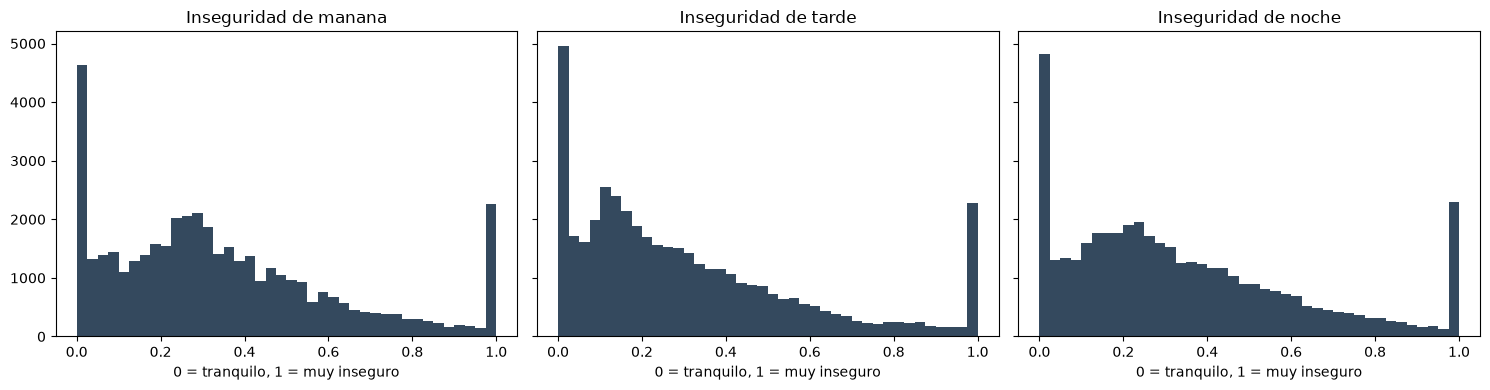

Calles que cambian más entre el día y la noche:


,nombre_via,inseguridad_manana,inseguridad_tarde,inseguridad_noche
38160,Carrera 35,0.295,0.345,1.0
18401,Carrera 79A,0.317,0.404,1.0
18402,Carrera 79A,0.317,0.404,1.0
11777,Calle 32D,0.339,0.486,1.0
11778,Calle 32D,0.339,0.486,1.0
37110,Calle 32E,0.343,0.429,1.0
37111,Calle 32E,0.343,0.429,1.0
16379,Carrera 33,0.347,0.423,1.0


In [14]:
# ¿Se nota la diferencia entre franjas? Comparamos las mismas calles a distintas horas.
fig, ejes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for eje, franja in zip(ejes, FRANJAS):
    eje.hist(aristas[f"inseguridad_{franja}"], bins=40, color="#34495e")
    eje.set_title(f"Inseguridad de {franja}")
    eje.set_xlabel("0 = tranquilo, 1 = muy inseguro")
plt.tight_layout(); plt.show()

print("Calles que cambian más entre el día y la noche:")
aristas["cambio_dia_noche"] = aristas["inseguridad_noche"] - aristas["inseguridad_manana"]
display(aristas.nlargest(8, "cambio_dia_noche")[
    ["nombre_via", "inseguridad_manana", "inseguridad_tarde", "inseguridad_noche"]].round(3))

### 7.2 Cámaras

In [15]:
arbol_camaras = cKDTree(np.c_[camaras["x"], camaras["y"]])

vecinos = arbol_camaras.query_ball_point(puntos_aristas, r=RADIO_CAMARAS)
aristas["camaras_cerca"] = np.array([len(v) for v in vecinos])
aristas["tiene_camara"] = (aristas["camaras_cerca"] > 0).astype(int)

print(f"Calles con al menos una cámara a menos de {RADIO_CAMARAS} m: "
      f"{aristas['tiene_camara'].sum():,} de {len(aristas):,} "
      f"({aristas['tiene_camara'].mean()*100:.1f}%)")

Calles con al menos una cámara a menos de 300 m: 3,584 de 43,100 (8.3%)


### 7.3 Velocidad

Si hay un sensor cerca usamos la velocidad **medida**. Si no, la velocidad teórica de OSM.
Con la velocidad y la distancia sale el tiempo: `tiempo = distancia / velocidad`.

In [16]:
arbol_sensores = cKDTree(np.c_[sensores["x"], sensores["y"]])

# Sensor más cercano a cada calle (distancia euclidiana en metros)
distancia_sensor, indice_sensor = arbol_sensores.query(puntos_aristas, k=1)

hay_sensor = distancia_sensor < RADIO_SENSORES
velocidad_sensor = sensores["velocidad_real"].values[indice_sensor]

aristas["velocidad_kmh"] = np.where(hay_sensor, velocidad_sensor, aristas["velocidad_osm"])
aristas["velocidad_kmh"] = aristas["velocidad_kmh"].clip(5, 120)
aristas["origen_velocidad"] = np.where(hay_sensor, "sensor", "osm")

# tiempo en segundos = metros / (km/h convertidos a m/s)
aristas["tiempo_s"] = aristas["distancia_m"] / (aristas["velocidad_kmh"] * 1000 / 3600)

print(aristas["origen_velocidad"].value_counts().to_string())
print(f"\nvelocidad media: {aristas['velocidad_kmh'].mean():.1f} km/h")
display(aristas[["nombre_via", "distancia_m", "velocidad_kmh", "tiempo_s", "origen_velocidad"]].head())

origen_velocidad
osm       23041
sensor    20059

velocidad media: 31.1 km/h


,nombre_via,distancia_m,velocidad_kmh,tiempo_s,origen_velocidad
0,NaN,0.682288,40.000000,0.061406,osm
1,NaN,0.843122,50.000000,0.060705,osm
2,Calle 32,1.075969,27.957841,0.138548,sensor
3,Calle 32,1.075969,27.957841,0.138548,sensor
4,Carrera 46,1.079102,30.000000,0.129492,osm


## 8. El peso de cada calle

Con toda la información pegada, definimos el costo. La idea en una frase:

> **Una calle insegura se siente más larga de lo que es. Una calle con cámara se siente
> un poco más corta.**

$$
\text{costo} = \text{distancia} \times (1 + \text{inseguridad} - 0.2 \times \text{tiene camara})
$$

donde el castigo se controla con un solo número, `PESO_INSEGURIDAD`.

Con `PESO_INSEGURIDAD = 4`, por una calle de 100 m con inseguridad máxima el algoritmo "paga"
500 m. Si además tiene cámara, 480 m. Y por una calle tranquila con cámara, 80 m.

¿Por qué 4 y no 1? Porque con 1 **la ruta no cambia**. Hay que castigar bastante para que al
algoritmo le compense dar un rodeo. Eso se comprueba en la sección 11.1, cuando ya tengamos los algoritmos listos.

Dos cosas que hay que respetar sí o sí:

* **El costo nunca puede ser negativo ni cero**, porque los algoritmos de búsqueda dejarían
  de funcionar. Por eso el factor se recorta con un mínimo de 0.1.
* **El costo nunca puede ser menor que la distancia real** en el caso base... salvo por el
  bono de cámara. Esto lo tenemos en cuenta más abajo, al construir la heurística de A\*.

In [17]:
# ======================================================================
# EL PESO DE CADA CALLE
# ======================================================================

PESO_INSEGURIDAD = 4.0    # cuánto castiga la inseguridad (4 = puede quintuplicar la distancia)
BONO_CAMARA = 0.2         # cuánto descuenta tener cámara cerca
FACTOR_MINIMO = 0.1       # suelo, para que el costo nunca sea 0 ni negativo

# Se calcula una columna de costo por franja. Son tres pesos distintos para
# el mismo grafo: la misma calle cuesta diferente según la hora.
for franja in FRANJAS:

    # factor = cuántas veces "se siente" más larga la calle de lo que es
    factor = (1                                                    # punto de partida: tal cual
              + PESO_INSEGURIDAD * aristas[f"inseguridad_{franja}"]  # castigo por inseguridad
              - BONO_CAMARA * aristas["tiene_camara"])              # descuento por cámara

    # El recorte es OBLIGATORIO, no cosmético: costo uniforme y A* dan por
    # sentado que ningún peso es negativo. Con un peso negativo el algoritmo
    # entraría en bucle buscando "ganar" costo dando vueltas.
    factor = factor.clip(lower=FACTOR_MINIMO)

    aristas[f"costo_{franja}"] = aristas["distancia_m"] * factor

print("Costo de la misma calle en cada franja (primeras filas):")
display(aristas[["nombre_via", "distancia_m", "tiene_camara",
                 "costo_manana", "costo_tarde", "costo_noche"]].head(8).round(1))

# Un dato que ayuda a entender la escala: si recorrieras TODAS las calles de
# Medellín, ¿cuántos kilómetros "sentirías" en cada franja?
print("\nCosto total de recorrer todas las calles de Medellín:")
for franja in FRANJAS:
    print(f"  {franja:8s} {aristas[f'costo_{franja}'].sum()/1000:>10,.0f} km equivalentes")
print(f"  {'real':8s} {aristas['distancia_m'].sum()/1000:>10,.0f} km de verdad")

Costo de la misma calle en cada franja (primeras filas):


,nombre_via,distancia_m,tiene_camara,costo_manana,costo_tarde,costo_noche
0,NaN,0.7,0,1.2,1.2,1.3
1,NaN,0.8,0,2.9,2.8,2.5
2,Calle 32,1.1,0,1.7,1.5,1.5
3,Calle 32,1.1,0,1.7,1.5,1.5
4,Carrera 46,1.1,0,2.9,2.6,3.3
5,NaN,1.1,0,2.1,2.1,2.2
6,Calle 48F,1.2,0,1.9,1.6,1.8
7,Calle 48F,1.2,0,1.9,1.6,1.8



Costo total de recorrer todas las calles de Medellín:
  manana        8,976 km equivalentes
  tarde         8,475 km equivalentes
  noche         8,866 km equivalentes
  real          4,236 km de verdad


## 9. Los algoritmos de búsqueda

Escritos a mano, sin usar `networkx`. Los tres comparten la misma estructura —una **frontera**
ordenada por prioridad— y solo se diferencian en **qué prioridad usan**:

| Algoritmo | Prioridad | Qué mira | ¿Encuentra el óptimo? |
|---|---|---|---|
| **Costo uniforme** | $g(n)$ | Lo que ya gastó | Sí |
| **Primero el mejor** | $h(n)$ | Lo que cree que falta | No |
| **A\*** | $g(n) + h(n)$ | Ambas cosas | Sí, si $h$ no se pasa |

donde:

* $g(n)$ = costo acumulado desde el origen hasta $n$
* $h(n)$ = estimación de lo que falta de $n$ hasta la meta

### La heurística

Como ya estamos en metros y en un plano, la estimación es la **distancia euclidiana** hasta
la meta, la de toda la vida:

$$h(n) = \sqrt{(x_n - x_{meta})^2 + (y_n - y_{meta})^2}$$

Para que A\* funcione bien, $h$ **nunca debe pasarse** de lo que realmente falta. Se cumple
porque la línea recta es siempre la distancia más corta posible entre dos puntos: por la calle
siempre vas a recorrer igual o más.

Con el costo de seguridad hay un detalle: el bono de cámara puede hacer que una calle cueste
un 20 % menos que su distancia. Para no pasarnos, la heurística se multiplica por 0.8.

In [18]:
def construir_vecinos(tabla_aristas, columna_costo):
    # Convierte la tabla de aristas en un diccionario:
    #    {nodo: [(vecino, costo), (vecino, costo), ...]}
    # Es la forma normal de representar un grafo para recorrerlo.
    vecinos = {}
    for origen, destino, costo in zip(tabla_aristas["origen"],
                                      tabla_aristas["destino"],
                                      tabla_aristas[columna_costo]):
        vecinos.setdefault(origen, []).append((destino, float(costo)))
    return vecinos


def reconstruir_camino(padre, inicio, meta):
    # Va del final hacia atrás siguiendo quién fue el padre de cada nodo
    if meta not in padre and meta != inicio:
        return None
    camino = [meta]
    while camino[-1] != inicio:
        camino.append(padre[camino[-1]])
    return camino[::-1]

In [19]:
# ======================================================================
# 1. BÚSQUEDA DE COSTO UNIFORME  (Dijkstra de toda la vida)
# ======================================================================
# Siempre saca de la frontera el nodo MÁS BARATO de los pendientes.
# No sabe dónde está la meta, así que se va expandiendo en círculo
# alrededor del origen hasta tropezarse con ella.

def costo_uniforme(vecinos, inicio, meta):
    frontera = [(0.0, inicio)]      # cola de prioridad: (costo acumulado, nodo)
    costo_hasta = {inicio: 0.0}     # el mejor costo conocido para llegar a cada nodo
    padre = {}                      # de dónde vinimos, para reconstruir el camino
    visitados = set()               # nodos ya cerrados: no se vuelven a tocar
    expandidos = 0                  # contador, para comparar algoritmos

    while frontera:
        # heappop devuelve siempre el de menor costo acumulado
        g, nodo = heapq.heappop(frontera)

        # Puede haber copias viejas del mismo nodo en la cola (metimos una
        # entrada nueva cada vez que encontramos un camino mejor). Si ya lo
        # cerramos, esta copia es basura y se ignora.
        if nodo in visitados:
            continue

        visitados.add(nodo)
        expandidos += 1

        # Al sacar la meta de la cola tenemos la garantía de que su costo es
        # el mínimo posible: cualquier otra ruta pendiente cuesta más o igual.
        if nodo == meta:
            break

        for vecino, costo in vecinos.get(nodo, []):
            nuevo_g = g + costo                              # lo que costaría llegar por aquí

            # ¿Es mejor que el mejor camino que conocíamos hasta ese vecino?
            if nuevo_g < costo_hasta.get(vecino, float("inf")):
                costo_hasta[vecino] = nuevo_g                # nos quedamos con el nuevo
                padre[vecino] = nodo                          # y con por dónde llegamos
                heapq.heappush(frontera, (nuevo_g, vecino))   # a la cola

    return reconstruir_camino(padre, inicio, meta), expandidos, costo_hasta.get(meta)

In [20]:
# ======================================================================
# 2. PRIMERO EL MEJOR  (best-first voraz)
# ======================================================================
# Solo mira la estimación h: va siempre hacia el nodo que PARECE más
# cerca de la meta, sin importarle lo que lleva gastado.
#
# Consecuencia: es rapidísimo (abre poquísimos nodos) pero NO garantiza
# la mejor ruta. Si se mete por una calle que apunta hacia la meta pero
# acaba dando un rodeo, no se entera.

def primero_el_mejor(vecinos, inicio, meta, heuristica):
    frontera = [(heuristica(inicio), inicio)]   # prioridad = SOLO lo estimado
    padre = {}
    visitados = set()
    expandidos = 0

    while frontera:
        # el guion bajo es la prioridad, que aquí no necesitamos para nada más
        _, nodo = heapq.heappop(frontera)

        if nodo in visitados:
            continue

        visitados.add(nodo)
        expandidos += 1

        if nodo == meta:
            break

        for vecino, _costo in vecinos.get(nodo, []):
            # Fíjate en que el costo NI SE MIRA (por eso se llama _costo).
            # Cada nodo se mete en la cola una sola vez y no se revisa después:
            # este algoritmo nunca se corrige a sí mismo.
            if vecino not in visitados and vecino not in padre:
                padre[vecino] = nodo
                heapq.heappush(frontera, (heuristica(vecino), vecino))

    return reconstruir_camino(padre, inicio, meta), expandidos, None

In [21]:
# ======================================================================
# 3. A ESTRELLA
# ======================================================================
# Junta los dos anteriores:  prioridad = g(n) + h(n)
#                                        |      |
#                        lo que ya gastó  ------+---- lo que estima que falta
#
# Es igual de exacto que costo uniforme (encuentra el óptimo) pero abre
# muchos menos nodos, porque la heurística lo va orientando hacia la meta
# en vez de dejarlo expandirse en todas direcciones.

def a_estrella(vecinos, inicio, meta, heuristica):
    frontera = [(heuristica(inicio), inicio)]   # al principio g=0, así que f = h
    costo_hasta = {inicio: 0.0}                 # este es el g(n)
    padre = {}
    visitados = set()
    expandidos = 0

    while frontera:
        _, nodo = heapq.heappop(frontera)       # el de menor f = g + h

        if nodo in visitados:
            continue

        visitados.add(nodo)
        expandidos += 1

        if nodo == meta:
            break

        g = costo_hasta[nodo]                   # lo que costó llegar hasta aquí

        for vecino, costo in vecinos.get(nodo, []):
            nuevo_g = g + costo                 # lo que costaría llegar al vecino

            if nuevo_g < costo_hasta.get(vecino, float("inf")):
                costo_hasta[vecino] = nuevo_g
                padre[vecino] = nodo
                # La diferencia con costo uniforme está justo aquí: a la
                # prioridad se le SUMA la estimación de lo que queda.
                heapq.heappush(frontera, (nuevo_g + heuristica(vecino), vecino))

    return reconstruir_camino(padre, inicio, meta), expandidos, costo_hasta.get(meta)

In [22]:
# ======================================================================
# LA HEURÍSTICA
# ======================================================================
# h(n) = cuánto CREEMOS que falta de n hasta la meta.
#
# La regla de oro: h NUNCA puede pasarse. Si sobreestima, A* puede
# descartar el camino bueno y devolver una ruta peor. Por eso usamos la
# distancia en línea recta, que es el mínimo absoluto: por la calle
# siempre vas a recorrer igual o más que en línea recta.
#
# ...con un matiz que se descubrió midiendo (ver la celda del punto medio):
# proyectar a EPSG:3116 estira las distancias un poco, porque Medellín está
# a ~1,5 grados del meridiano central de esa proyección. El estiramiento es
# de como mucho un 0,155%, y en 9.351 de 43.284 calles hace que la recta
# proyectada salga MAYOR que la longitud real de OSM. Es minúsculo, pero
# rompe la garantía. Se arregla con un factor de seguridad.
MARGEN_PROYECCION = 0.998      # 0,2% de colchón, por encima del 0,155% medido

# Diccionario {id_nodo: {"x": ..., "y": ...}} para no tocar el DataFrame
# dentro del bucle de búsqueda, que sería lentísimo.
coordenadas = nodos.set_index("id_nodo")[["x", "y"]].to_dict("index")

def crear_heuristica(meta, tipo="distancia"):
    # Devuelve una función h(nodo). Se crea una por cada meta, porque la
    # posición del destino queda "congelada" dentro.
    x_meta = coordenadas[meta]["x"]
    y_meta = coordenadas[meta]["y"]

    if tipo == "tiempo":
        # Si el costo son SEGUNDOS, la estimación también tiene que estar en
        # segundos. Se divide por la velocidad más alta de toda la red: así
        # el tiempo estimado es el mínimo imaginable y nunca nos pasamos.
        velocidad_tope = aristas["velocidad_kmh"].max() * 1000 / 3600   # a m/s
        escala = 1.0 / velocidad_tope

    elif tipo == "seguridad":
        # El costo de seguridad es distancia x factor. El factor más bajo
        # posible es (1 - BONO_CAMARA) = 0.8, cuando la calle es tranquila y
        # además tiene cámara. Multiplicamos por 0.8 para cubrir ese caso.
        escala = 1.0 - BONO_CAMARA

    else:
        # Si el costo son metros, la distancia en metros vale tal cual.
        escala = 1.0

    def h(nodo):
        dx = coordenadas[nodo]["x"] - x_meta        # diferencia en metros
        dy = coordenadas[nodo]["y"] - y_meta
        # Pitágoras, a escala, y con el colchón de la proyección
        return np.sqrt(dx*dx + dy*dy) * escala * MARGEN_PROYECCION

    return h

## 10. Buscar una ruta

Falta juntar las piezas: dado un punto en el mapa, encontrar el nodo más cercano; y dado
un camino, calcular cuánto mide, cuánto tarda y qué tan inseguro es.

In [23]:
# Árbol de nodos para encontrar el más cercano a un punto cualquiera
arbol_nodos = cKDTree(nodos[["x", "y"]].values)

LUGARES = {
    "Parque Berrío":        (6.25060, -75.56820),
    "Parque de El Poblado": (6.20940, -75.56760),
    "Estadio":              (6.25640, -75.59000),
    "Universidad de Antioquia": (6.26760, -75.56880),
    "San Javier":           (6.25580, -75.61680),
    "Terminal del Norte":   (6.27950, -75.56770),
    "Centro Comercial Santafé": (6.19750, -75.57450),
    "Aeropuerto Olaya Herrera": (6.21990, -75.59060),
}

def buscar_nodo(lugar):
    # Acepta un nombre de LUGARES o una tupla (lat, lon)
    lat, lon = LUGARES[lugar] if isinstance(lugar, str) else lugar
    x, y = a_metros.transform(lon, lat)          # a metros, que es donde vive el árbol
    _, indice = arbol_nodos.query([x, y], k=1)
    return int(nodos.iloc[indice]["id_nodo"])


# Diccionario para buscar los datos de una calle rápido: (origen, destino) -> fila
datos_arista = aristas.set_index(["origen", "destino"])

def resumir_camino(camino, franja):
    # Recorre el camino sumando distancia y tiempo, y promediando la inseguridad
    tramos = list(zip(camino[:-1], camino[1:]))
    filas = datos_arista.loc[tramos]

    distancia = filas["distancia_m"].sum()
    return {
        "tramos": len(tramos),
        "distancia_km": round(distancia / 1000, 2),
        "tiempo_min": round(filas["tiempo_s"].sum() / 60, 1),
        # promedio ponderado: una calle larga pesa más que una corta
        "inseguridad_media": round(
            np.average(filas[f"inseguridad_{franja}"], weights=filas["distancia_m"]), 3),
        "calles_con_camara": int(filas["tiene_camara"].sum()),
        "robos_cerca": int(filas[f"robos_{franja}"].sum()),
    }

## 11. Comparar las cuatro rutas

Ahora sí: mismo origen, mismo destino, cuatro formas de decidir.

| Ruta | Costo que minimiza |
|---|---|
| **Más corta** | metros |
| **Más rápida** | segundos |
| **Más segura** | metros castigados por inseguridad |

In [24]:
ORIGEN = "San Javier"
DESTINO = "Parque de El Poblado"
FRANJA_ACTUAL = "noche"          # cambiar a "manana" o "tarde" para comparar

nodo_inicio = buscar_nodo(ORIGEN)
nodo_meta = buscar_nodo(DESTINO)

print(f"De: {ORIGEN}  (nodo {nodo_inicio})")
print(f"A:  {DESTINO} (nodo {nodo_meta})")

# Distancia en línea recta, para tener una referencia
x1, y1 = coordenadas[nodo_inicio]["x"], coordenadas[nodo_inicio]["y"]
x2, y2 = coordenadas[nodo_meta]["x"], coordenadas[nodo_meta]["y"]
print(f"En línea recta: {np.sqrt((x2-x1)**2 + (y2-y1)**2)/1000:.2f} km")

De: San Javier  (nodo 1235062121)
A:  Parque de El Poblado (nodo 309026275)
En línea recta: 7.54 km


In [25]:
CONFIGURACIONES = {
    "Más corta":  ("distancia_m",            "distancia"),
    "Más rápida": ("tiempo_s",               "tiempo"),
    "Más segura": (f"costo_{FRANJA_ACTUAL}", "seguridad"),
}

rutas = {}
resumenes = []

for nombre, (columna_costo, tipo_heuristica) in CONFIGURACIONES.items():
    vecinos = construir_vecinos(aristas, columna_costo)
    heuristica = crear_heuristica(nodo_meta, tipo_heuristica)

    camino, expandidos, _ = a_estrella(vecinos, nodo_inicio, nodo_meta, heuristica)

    rutas[nombre] = camino
    resumen = resumir_camino(camino, FRANJA_ACTUAL)
    resumen["ruta"] = nombre
    resumen["nodos_expandidos"] = expandidos
    resumenes.append(resumen)

tabla = pd.DataFrame(resumenes).set_index("ruta")
print(f"Franja: {FRANJA_ACTUAL}\n")
display(tabla)

Franja: noche



,tramos,distancia_km,tiempo_min,inseguridad_media,calles_con_camara,robos_cerca,nodos_expandidos
ruta,,,,,,,
Más corta,134,9.03,21.8,0.569,43,54591,3285
Más rápida,98,9.81,18.0,0.586,30,49619,7326
Más segura,157,11.37,22.8,0.392,28,48092,11495


### 11.1 ¿Cuánto hay que castigar para que la ruta cambie?

Vale la pena comprobarlo en vez de suponerlo. Se prueban varios valores de `PESO_INSEGURIDAD`
y se mira si la ruta se mueve.

In [26]:
# OJO: esta celda tarda un poco porque corre A* varias veces sobre toda la ciudad.
from copy import copy

pruebas = []
for peso in [0, 1, 2, 4, 8]:
    factor = (1 + peso * aristas["inseguridad_noche"]
                - BONO_CAMARA * aristas["tiene_camara"]).clip(lower=FACTOR_MINIMO)
    aristas["costo_prueba"] = aristas["distancia_m"] * factor

    vecinos_prueba = construir_vecinos(aristas, "costo_prueba")
    heuristica_prueba = crear_heuristica(buscar_nodo("Parque de El Poblado"), "seguridad")
    camino_prueba, _, _ = a_estrella(vecinos_prueba,
                                     buscar_nodo("San Javier"),
                                     buscar_nodo("Parque de El Poblado"),
                                     heuristica_prueba)
    r = resumir_camino(camino_prueba, "noche")
    r["peso"] = peso
    pruebas.append(r)

aristas.drop(columns=["costo_prueba"], inplace=True)
tabla_pruebas = pd.DataFrame(pruebas).set_index("peso")
display(tabla_pruebas[["distancia_km", "tiempo_min", "inseguridad_media", "calles_con_camara"]])

print("Con pesos de 0 a 2 la ruta es la misma: no le compensa desviarse.")
print("A partir de 4 sí cambia, y baja la inseguridad a costa de más kilómetros.")
print("Por eso el valor por defecto es 4 y no 1.")

,distancia_km,tiempo_min,inseguridad_media,calles_con_camara
peso,,,,
0,9.03,21.8,0.569,43
1,9.03,21.8,0.568,42
2,9.03,21.8,0.568,42
4,11.37,22.8,0.392,28
8,11.49,22.9,0.385,20


Con pesos de 0 a 2 la ruta es la misma: no le compensa desviarse.
A partir de 4 sí cambia, y baja la inseguridad a costa de más kilómetros.
Por eso el valor por defecto es 4 y no 1.


## 12. Comparar los tres algoritmos

Misma ruta, mismo costo, tres formas de buscarla. Lo interesante es ver **cuántos nodos
tiene que abrir cada uno** y si llegan o no a la solución óptima.

In [27]:
columna = f"costo_{FRANJA_ACTUAL}"
vecinos = construir_vecinos(aristas, columna)
heuristica = crear_heuristica(nodo_meta, "seguridad")

resultados = []

camino, expandidos, costo = costo_uniforme(vecinos, nodo_inicio, nodo_meta)
resultados.append({"algoritmo": "Costo uniforme", "nodos_expandidos": expandidos,
                   "costo_total": round(costo, 1), "tramos": len(camino) - 1})

camino_bf, expandidos_bf, _ = primero_el_mejor(vecinos, nodo_inicio, nodo_meta, heuristica)
costo_bf = sum(datos_arista.loc[(a, b), columna]
               for a, b in zip(camino_bf[:-1], camino_bf[1:]))
resultados.append({"algoritmo": "Primero el mejor", "nodos_expandidos": expandidos_bf,
                   "costo_total": round(costo_bf, 1), "tramos": len(camino_bf) - 1})

camino_a, expandidos_a, costo_a = a_estrella(vecinos, nodo_inicio, nodo_meta, heuristica)
resultados.append({"algoritmo": "A*", "nodos_expandidos": expandidos_a,
                   "costo_total": round(costo_a, 1), "tramos": len(camino_a) - 1})

comparacion = pd.DataFrame(resultados).set_index("algoritmo")
display(comparacion)

optimo = comparacion["costo_total"].min()
print(f"\nCosto óptimo: {optimo:,.0f}")
print(f"A* expandió un {(1 - expandidos_a/expandidos)*100:.0f}% menos de nodos que costo uniforme,")
print(f"y llegó al mismo resultado: {abs(costo_a - costo) < 0.01}")
print(f"\nPrimero el mejor abrió solo {expandidos_bf:,} nodos (el que menos),")
print(f"pero su ruta cuesta un {(costo_bf/optimo - 1)*100:.1f}% más que la óptima.")
print("Eso es exactamente lo que se espera: es el más rápido pero no garantiza nada.")

,nodos_expandidos,costo_total,tramos
algoritmo,,,
Costo uniforme,14953,28717.7,157
Primero el mejor,167,36234.6,141
A*,11495,28717.7,157



Costo óptimo: 28,718
A* expandió un 23% menos de nodos que costo uniforme,
y llegó al mismo resultado: True

Primero el mejor abrió solo 167 nodos (el que menos),
pero su ruta cuesta un 26.2% más que la óptima.
Eso es exactamente lo que se espera: es el más rápido pero no garantiza nada.


## 13. La misma ruta a distintas horas

Aquí se ve si separar por franjas sirvió de algo: la ruta "más segura" debería cambiar
entre la mañana y la noche.

In [28]:
rutas_por_franja = {}
filas = []

for franja in FRANJAS:
    vecinos = construir_vecinos(aristas, f"costo_{franja}")
    heuristica = crear_heuristica(nodo_meta, "seguridad")
    camino, _, _ = a_estrella(vecinos, nodo_inicio, nodo_meta, heuristica)

    rutas_por_franja[franja] = camino
    resumen = resumir_camino(camino, franja)
    resumen["franja"] = franja
    filas.append(resumen)

display(pd.DataFrame(filas).set_index("franja"))

# ¿Son rutas distintas o la misma?
print("\n¿Cambia la ruta según la hora?")
for a in FRANJAS:
    for b in FRANJAS:
        if a < b:
            iguales = rutas_por_franja[a] == rutas_por_franja[b]
            print(f"  {a} vs {b}: {'misma ruta' if iguales else 'RUTAS DISTINTAS'}")

,tramos,distancia_km,tiempo_min,inseguridad_media,calles_con_camara,robos_cerca
franja,,,,,,
manana,136,9.09,22.3,0.531,41,21493
tarde,138,9.21,22.5,0.506,33,25031
noche,157,11.37,22.8,0.392,28,48092



¿Cambia la ruta según la hora?
  manana vs tarde: RUTAS DISTINTAS
  manana vs noche: RUTAS DISTINTAS
  noche vs tarde: RUTAS DISTINTAS


## 14. El mapa

In [29]:
COLORES = {"Más corta": "#8e44ad", "Más rápida": "#2980b9", "Más segura": "#27ae60"}

# Para dibujar necesitamos grados otra vez (Folium no entiende metros)
grados = nodos.set_index("id_nodo")[["lat", "lon"]].to_dict("index")

def coordenadas_camino(camino):
    return [(grados[n]["lat"], grados[n]["lon"]) for n in camino]

def dibujar_mapa(rutas, franja):
    centro = coordenadas_camino(list(rutas.values())[0])
    mapa = folium.Map(location=centro[len(centro)//2], zoom_start=13, tiles="cartodbpositron")

    # Las rutas
    for nombre, camino in rutas.items():
        resumen = resumir_camino(camino, franja)
        folium.PolyLine(
            coordenadas_camino(camino),
            color=COLORES.get(nombre, "#e67e22"), weight=6, opacity=0.8,
            tooltip=(f"<b>{nombre}</b><br>{resumen['distancia_km']} km · "
                     f"{resumen['tiempo_min']} min<br>"
                     f"inseguridad {resumen['inseguridad_media']}")
        ).add_to(mapa)

    # Las cámaras
    grupo = folium.FeatureGroup(name="Cámaras", show=False)
    for _, c in camaras.iterrows():
        folium.CircleMarker([c["latitud"], c["longitud"]], radius=4,
                            color="#27ae60", fill=True, fill_opacity=0.9,
                            popup=str(c.get("Dirección", ""))).add_to(grupo)
    grupo.add_to(mapa)

    folium.Marker(centro[0], tooltip="Origen",
                  icon=folium.Icon(color="green")).add_to(mapa)
    folium.Marker(centro[-1], tooltip="Destino",
                  icon=folium.Icon(color="red")).add_to(mapa)
    folium.LayerControl().add_to(mapa)
    return mapa

mapa = dibujar_mapa(rutas, FRANJA_ACTUAL)
mapa.save(CARPETA_SALIDA / "rutas.html")
print("Guardado en salidas/rutas.html")
mapa

Guardado en salidas/rutas.html


## 15. Todo junto en una función

Para no tener que reejecutar el análisis cada vez que se quiere probar un par de puntos.

In [30]:
def buscar_ruta(origen, destino, franja="noche", criterio="seguridad",
                algoritmo="a_estrella", ver_mapa=True):
    # criterio:  "distancia" | "tiempo" | "seguridad"
    # algoritmo: "a_estrella" | "costo_uniforme" | "primero_el_mejor"

    columnas = {"distancia": "distancia_m",
                "tiempo": "tiempo_s",
                "seguridad": f"costo_{franja}"}
    columna = columnas[criterio]

    nodo_a = buscar_nodo(origen)
    nodo_b = buscar_nodo(destino)

    vecinos = construir_vecinos(aristas, columna)
    heuristica = crear_heuristica(nodo_b, criterio)

    if algoritmo == "costo_uniforme":
        camino, expandidos, _ = costo_uniforme(vecinos, nodo_a, nodo_b)
    elif algoritmo == "primero_el_mejor":
        camino, expandidos, _ = primero_el_mejor(vecinos, nodo_a, nodo_b, heuristica)
    else:
        camino, expandidos, _ = a_estrella(vecinos, nodo_a, nodo_b, heuristica)

    resumen = resumir_camino(camino, franja)
    resumen["nodos_expandidos"] = expandidos
    print(f"{origen} -> {destino}  ({criterio}, {franja}, {algoritmo})")
    print(pd.Series(resumen).to_string())

    if ver_mapa:
        return camino, resumen, dibujar_mapa({criterio.capitalize(): camino}, franja)
    return camino, resumen, None


camino, resumen, mapa = buscar_ruta("Universidad de Antioquia", "Centro Comercial Santafé",
                                    franja="noche", criterio="seguridad")
mapa

Universidad de Antioquia -> Centro Comercial Santafé  (seguridad, noche, a_estrella)
tramos                  79.000
distancia_km            10.460
tiempo_min              18.300
inseguridad_media        0.415
calles_con_camara        9.000
robos_cerca          15953.000
nodos_expandidos     12951.000


## 16. Mapa de calor de seguridad

Un mapa aparte, solo para mirar los datos: dónde están las zonas peligrosas, qué vías las
atraviesan y dónde hay cámaras. Se guarda en `salidas/mapa_seguridad.html`.

In [31]:
# ======================================================================
# MAPA DE CALOR DE SEGURIDAD
# ======================================================================
# Tres capas superpuestas que se encienden y apagan desde el control de
# arriba a la derecha:
#   1. Zonas inseguras -> heatmap con los propios puntos de robo, una capa
#                         por franja, para ver cómo se mueve el peligro.
#   2. Vías peligrosas -> las calles del grafo pintadas por su inseguridad.
#   3. Cámaras         -> dónde hay fotodetección.

from folium.plugins import HeatMap

def color_por_inseguridad(valor):
    # Escala de verde a rojo. Los cortes son los cuartiles aproximados
    # de la distribución, para que los colores se repartan bien.
    if valor < 0.20: return "#1a9850"   # tranquilo
    if valor < 0.35: return "#a6d96a"
    if valor < 0.50: return "#fee08b"   # medio
    if valor < 0.70: return "#fc8d59"
    return "#d73027"                    # muy inseguro


mapa_calor = folium.Map(location=[6.25, -75.575], zoom_start=12,
                        tiles="cartodbdark_matter")

# ---------------------------------------------------------------------
# CAPA 1: zonas inseguras (heatmap de los robos, una por franja)
# ---------------------------------------------------------------------
for nombre_franja in FRANJAS:
    grupo = folium.FeatureGroup(name=f"Zonas inseguras - {nombre_franja}",
                                show=(nombre_franja == FRANJA_ACTUAL))

    # Se usa una muestra: dibujar 75.000 puntos hace el archivo enorme
    # y el navegador no lo agradece. 15.000 ya da la misma forma.
    puntos = robos[robos["franja"] == nombre_franja]
    if len(puntos) > 15000:
        puntos = puntos.sample(15000, random_state=1)

    HeatMap(puntos[["latitud", "longitud"]].values.tolist(),
            radius=12, blur=18, min_opacity=0.2).add_to(grupo)
    grupo.add_to(mapa_calor)

# ---------------------------------------------------------------------
# CAPA 2: las vías, pintadas según su inseguridad
# ---------------------------------------------------------------------
# Truco de tamaño: en vez de crear un objeto PolyLine por calle (serían
# decenas de miles y el HTML se iba a 15 MB), se AGRUPAN las calles por
# color y se crea UNA sola PolyLine por grupo, pasándole la lista de
# segmentos. Folium lo admite y el archivo baja de 15 MB a menos de 2.
# Lo que se pierde es el tooltip por calle; a cambio el mapa abre al vuelo.

UMBRAL_DIBUJO = 0.35        # por debajo de esto la calle no se dibuja

coordenadas_grados = nodos.set_index("id_nodo")[["lat", "lon"]].to_dict("index")

# Un cubo de segmentos por cada color de la escala
segmentos_por_color = {}
dibujadas = 0

for fila in aristas.itertuples():
    inseguridad = getattr(fila, f"inseguridad_{FRANJA_ACTUAL}")
    if inseguridad < UMBRAL_DIBUJO:
        continue

    punto_a = coordenadas_grados[fila.origen]
    punto_b = coordenadas_grados[fila.destino]

    color = color_por_inseguridad(inseguridad)
    segmentos_por_color.setdefault(color, []).append(
        [(punto_a["lat"], punto_a["lon"]), (punto_b["lat"], punto_b["lon"])]
    )
    dibujadas += 1

grupo_vias = folium.FeatureGroup(name=f"Vías peligrosas ({FRANJA_ACTUAL})", show=True)

# Las más peligrosas se dibujan al final para que queden por encima
ORDEN = ["#1a9850", "#a6d96a", "#fee08b", "#fc8d59", "#d73027"]
GROSOR = {"#1a9850": 1.5, "#a6d96a": 2, "#fee08b": 2.5, "#fc8d59": 3, "#d73027": 4}

for color in ORDEN:
    if color not in segmentos_por_color:
        continue
    folium.PolyLine(
        segmentos_por_color[color],       # lista de segmentos, no un solo trazo
        color=color,
        weight=GROSOR[color],
        opacity=0.75,
    ).add_to(grupo_vias)

grupo_vias.add_to(mapa_calor)

# ---------------------------------------------------------------------
# CAPA 3: cámaras
# ---------------------------------------------------------------------
grupo_camaras = folium.FeatureGroup(name="Cámaras de fotodetección", show=True)
for camara in camaras.itertuples():
    folium.CircleMarker(
        [camara.latitud, camara.longitud],
        radius=5, color="#00e676", fill=True, fill_color="#00e676", fill_opacity=1, weight=1,
        tooltip="Cámara de fotodetección"
    ).add_to(grupo_camaras)
grupo_camaras.add_to(mapa_calor)

# ---------------------------------------------------------------------
# Leyenda
# ---------------------------------------------------------------------
leyenda = """
<div style="position:fixed; bottom:25px; left:25px; z-index:9999;
            background:rgba(20,20,20,.88); color:#eee; padding:12px 14px;
            border-radius:6px; font:12px system-ui; line-height:1.7;">
  <b>Inseguridad de la vía</b><br>
  <span style="color:#1a9850">&#9632;</span> muy baja &nbsp;
  <span style="color:#a6d96a">&#9632;</span> baja<br>
  <span style="color:#fee08b">&#9632;</span> media &nbsp;
  <span style="color:#fc8d59">&#9632;</span> alta<br>
  <span style="color:#d73027">&#9632;</span> muy alta &nbsp;
  <span style="color:#00e676">&#9679;</span> cámara
</div>
"""
mapa_calor.get_root().html.add_child(folium.Element(leyenda))

folium.LayerControl(collapsed=False).add_to(mapa_calor)
mapa_calor.save(CARPETA_SALIDA / "mapa_seguridad.html")

print(f"Vías dibujadas: {dibujadas:,} de {len(aristas):,} "
      f"(las que superan {UMBRAL_DIBUJO} de inseguridad)")
print(f"Cámaras: {len(camaras)}")
print("Guardado en salidas/mapa_seguridad.html")
mapa_calor

Vías dibujadas: 17,458 de 43,100 (las que superan 0.35 de inseguridad)
Cámaras: 51
Guardado en salidas/mapa_seguridad.html


## 17. Un ruteador interactivo

Hasta aquí, para probar una ruta hay que editar una celda y reejecutar. Esta sección genera
un **HTML autónomo** en el que se hace clic en el mapa para poner origen y destino, y la ruta
sale al instante.

El truco es que **A\\* va escrito en JavaScript** dentro del propio archivo: se vuelca el grafo
a JSON, se incrusta en la página y el navegador hace la búsqueda. El resultado funciona con
doble clic, sin Python de por medio.

Se puede cambiar al vuelo la franja horaria, el criterio (distancia, tiempo o seguridad) y el
algoritmo, y ver cómo cambia la ruta y cuántos nodos abre cada uno.

In [32]:
# ======================================================================
# PLANTILLA DEL FRONT INTERACTIVO
# ======================================================================
# Es el HTML + JavaScript del ruteador. Los huecos __DATOS__, __PESO__,
# __BONO__ y __FACTORMIN__ los rellena la celda siguiente.
# Va aqui dentro para que el notebook siga siendo autosuficiente.

PLANTILLA_FRONT = r'''<!DOCTYPE html>
<html lang="es">
<head>
<meta charset="utf-8">
<title>Ruteador de Medellín</title>
<link rel="stylesheet" href="https://cdnjs.cloudflare.com/ajax/libs/leaflet/1.9.4/leaflet.min.css">
<script src="https://cdnjs.cloudflare.com/ajax/libs/leaflet/1.9.4/leaflet.min.js"></script>
<style>
  * { box-sizing: border-box; }
  body { margin:0; font-family: system-ui, -apple-system, "Segoe UI", sans-serif;
         display:flex; height:100vh; background:#1b1f24; color:#e6e6e6; }
  #panel { width:320px; padding:18px; overflow-y:auto; background:#22272e;
           border-right:1px solid #333; flex-shrink:0; }
  #mapa { flex:1; }
  h1 { font-size:17px; margin:0 0 4px; }
  .sub { font-size:12px; color:#9aa4b0; margin-bottom:18px; line-height:1.5; }
  .grupo { margin-bottom:16px; }
  .grupo > label { display:block; font-size:11px; text-transform:uppercase;
                   letter-spacing:.06em; color:#8b949e; margin-bottom:6px; }
  .ops { display:flex; gap:4px; flex-wrap:wrap; }
  .ops button { flex:1; min-width:70px; padding:7px 4px; font-size:12px; cursor:pointer;
                background:#2d333b; color:#c9d1d9; border:1px solid #444c56; border-radius:5px; }
  .ops button.on { background:#2f81f7; border-color:#2f81f7; color:#fff; font-weight:600; }
  #limpiar { width:100%; padding:9px; margin-top:4px; cursor:pointer; font-size:13px;
             background:#3a2a2a; color:#f0b0b0; border:1px solid #5a3a3a; border-radius:5px; }
  #estado { font-size:12px; padding:10px; background:#1b1f24; border-radius:5px;
            border:1px solid #333; line-height:1.6; margin-bottom:14px; }
  table { width:100%; font-size:12px; border-collapse:collapse; }
  td { padding:5px 2px; border-bottom:1px solid #2d333b; }
  td:last-child { text-align:right; font-weight:600; font-variant-numeric:tabular-nums; }
  .pista { font-size:11px; color:#7d8590; margin-top:14px; line-height:1.5; }
</style>
</head>
<body>

<div id="panel">
  <h1>Ruteador de Medellín</h1>
  <div class="sub">Haz clic en el mapa para poner el <b style="color:#3fb950">origen</b>,
     y otra vez para el <b style="color:#f85149">destino</b>.</div>

  <div id="estado">Esperando el origen…</div>

  <div class="grupo">
    <label>Franja horaria</label>
    <div class="ops" id="ops-franja">
      <button data-v="manana">Mañana</button>
      <button data-v="tarde">Tarde</button>
      <button data-v="noche" class="on">Noche</button>
    </div>
  </div>

  <div class="grupo">
    <label>Qué minimizar</label>
    <div class="ops" id="ops-criterio">
      <button data-v="distancia">Distancia</button>
      <button data-v="tiempo">Tiempo</button>
      <button data-v="seguridad" class="on">Seguridad</button>
    </div>
  </div>

  <div class="grupo">
    <label>Algoritmo</label>
    <div class="ops" id="ops-algoritmo">
      <button data-v="a_estrella" class="on">A*</button>
      <button data-v="uniforme">Costo unif.</button>
      <button data-v="mejor">1.º mejor</button>
    </div>
  </div>

  <button id="limpiar">Borrar y empezar de nuevo</button>

  <table id="tabla"></table>

  <div class="pista">
    Las <span style="color:#3fb950">cámaras</span> se pueden encender en el control de capas,
    arriba a la derecha. Con criterio <b>seguridad</b> la ruta cambia según la franja.
  </div>
</div>

<div id="mapa"></div>

<script>
// ======================================================================
// DATOS  (inyectados desde el notebook)
// ======================================================================
// nodos:   [lat, lon, lat, lon, ...]                        paso 2
// aristas: [origen, destino, dist_m, tiempo_s, i_man, i_tar, i_noc, camara]  paso 8
//          las inseguridades vienen multiplicadas por 1000 para ahorrar espacio
const DATOS = __DATOS__;

const PESO_INSEGURIDAD = __PESO__;
const BONO_CAMARA      = __BONO__;
const FACTOR_MINIMO    = __FACTORMIN__;

const N = DATOS.nodos.length / 2;
const M = DATOS.aristas.length / 8;

// ======================================================================
// LISTA DE ADYACENCIA
// ======================================================================
// Se construye una sola vez al cargar. Formato CSR: para el nodo i, sus
// aristas van de inicio[i] hasta inicio[i+1] dentro del array 'destino'.
const grado = new Int32Array(N);
for (let e = 0; e < M; e++) grado[DATOS.aristas[e*8]]++;

const inicio = new Int32Array(N + 1);
for (let i = 0; i < N; i++) inicio[i+1] = inicio[i] + grado[i];

const destino  = new Int32Array(M);
const idArista = new Int32Array(M);
const cursor   = Int32Array.from(inicio.subarray(0, N));
for (let e = 0; e < M; e++) {
  const u = DATOS.aristas[e*8], k = cursor[u]++;
  destino[k]  = DATOS.aristas[e*8 + 1];
  idArista[k] = e;
}

// ======================================================================
// COSTO DE UNA ARISTA
// ======================================================================
function costo(e, criterio, franja) {
  const dist = DATOS.aristas[e*8 + 2];
  if (criterio === "distancia") return dist;
  if (criterio === "tiempo")    return DATOS.aristas[e*8 + 3];

  // seguridad: la calle insegura "se siente" más larga
  const col = franja === "manana" ? 4 : franja === "tarde" ? 5 : 6;
  const inseguridad = DATOS.aristas[e*8 + col] / 1000;
  const camara      = DATOS.aristas[e*8 + 7];
  let factor = 1 + PESO_INSEGURIDAD * inseguridad - BONO_CAMARA * camara;
  if (factor < FACTOR_MINIMO) factor = FACTOR_MINIMO;
  return dist * factor;
}

// ======================================================================
// MONTÍCULO BINARIO  (la cola de prioridad de la frontera)
// ======================================================================
class Monticulo {
  constructor() { this.p = []; this.v = []; }
  get tam() { return this.v.length; }
  meter(prioridad, valor) {
    this.p.push(prioridad); this.v.push(valor);
    let i = this.v.length - 1;
    while (i > 0) {
      const padre = (i - 1) >> 1;
      if (this.p[padre] <= this.p[i]) break;
      this.intercambiar(i, padre); i = padre;
    }
  }
  sacar() {
    const raiz = this.v[0];
    const ultP = this.p.pop(), ultV = this.v.pop();
    if (this.v.length) {
      this.p[0] = ultP; this.v[0] = ultV;
      let i = 0;
      for (;;) {
        const izq = 2*i + 1, der = izq + 1;
        let menor = i;
        if (izq < this.v.length && this.p[izq] < this.p[menor]) menor = izq;
        if (der < this.v.length && this.p[der] < this.p[menor]) menor = der;
        if (menor === i) break;
        this.intercambiar(i, menor); i = menor;
      }
    }
    return raiz;
  }
  intercambiar(a, b) {
    [this.p[a], this.p[b]] = [this.p[b], this.p[a]];
    [this.v[a], this.v[b]] = [this.v[b], this.v[a]];
  }
}

// ======================================================================
// DISTANCIA EN LÍNEA RECTA  (para la heurística)
// ======================================================================
// Como Medellín es pequeña, se puede aproximar el plano así: un grado de
// latitud son ~110.950 m y uno de longitud, a 6°N, son ~110.320 m.
const M_POR_GRADO_LAT = 110950, M_POR_GRADO_LON = 110320;

// Colchón de seguridad: la aproximación del plano puede quedarse un pelín
// larga y la heurística no debe pasarse nunca de lo que falta de verdad.
const MARGEN = 0.998;

function recta(a, b) {
  const dy = (DATOS.nodos[a*2]     - DATOS.nodos[b*2])     * M_POR_GRADO_LAT;
  const dx = (DATOS.nodos[a*2 + 1] - DATOS.nodos[b*2 + 1]) * M_POR_GRADO_LON;
  return Math.sqrt(dx*dx + dy*dy);
}

// ======================================================================
// BÚSQUEDA
// ======================================================================
// Los tres algoritmos comparten el bucle y solo cambian la prioridad:
//   uniforme  -> g          (lo gastado)
//   mejor     -> h          (lo estimado)
//   a_estrella-> g + h      (las dos)
function buscar(origen, meta, criterio, franja, algoritmo) {
  const g = new Float64Array(N).fill(Infinity);
  const padre = new Int32Array(N).fill(-1);
  const cerrado = new Uint8Array(N);

  // escala de la heurística, para que nunca se pase de lo que falta de verdad
  let escala = 1;
  if (criterio === "tiempo") {
    escala = 1 / (DATOS.velocidadMaxima * 1000 / 3600);
  } else if (criterio === "seguridad") {
    escala = 1 - BONO_CAMARA;
  }
  const h = (n) => recta(n, meta) * escala * MARGEN;

  const frontera = new Monticulo();
  g[origen] = 0;
  frontera.meter(algoritmo === "uniforme" ? 0 : h(origen), origen);

  let expandidos = 0;
  while (frontera.tam) {
    const n = frontera.sacar();
    if (cerrado[n]) continue;
    cerrado[n] = 1; expandidos++;
    if (n === meta) break;

    for (let k = inicio[n]; k < inicio[n+1]; k++) {
      const v = destino[k];
      if (cerrado[v]) continue;

      if (algoritmo === "mejor") {
        // el voraz no mira lo gastado: solo abre cada nodo una vez
        if (padre[v] === -1 && v !== origen) {
          padre[v] = n;
          frontera.meter(h(v), v);
        }
        continue;
      }

      const nuevoG = g[n] + costo(idArista[k], criterio, franja);
      if (nuevoG < g[v]) {
        g[v] = nuevoG;
        padre[v] = n;
        frontera.meter(algoritmo === "uniforme" ? nuevoG : nuevoG + h(v), v);
      }
    }
  }

  if (padre[meta] === -1 && meta !== origen) return null;

  // reconstruir el camino hacia atrás
  const camino = [meta];
  while (camino[camino.length - 1] !== origen) {
    const p = padre[camino[camino.length - 1]];
    if (p === -1) return null;
    camino.push(p);
  }
  camino.reverse();
  return { camino, expandidos };
}

// ======================================================================
// NODO MÁS CERCANO A UN CLIC
// ======================================================================
function nodoCercano(lat, lon) {
  let mejor = -1, mejorD = Infinity;
  for (let i = 0; i < N; i++) {
    const dy = (DATOS.nodos[i*2] - lat) * M_POR_GRADO_LAT;
    const dx = (DATOS.nodos[i*2 + 1] - lon) * M_POR_GRADO_LON;
    const d = dx*dx + dy*dy;                 // sin raíz: solo comparamos
    if (d < mejorD) { mejorD = d; mejor = i; }
  }
  return mejor;
}

// busca la arista que une dos nodos, para poder sumar sus datos
function aristaEntre(u, v) {
  for (let k = inicio[u]; k < inicio[u+1]; k++) {
    if (destino[k] === v) return idArista[k];
  }
  return -1;
}

// ======================================================================
// MAPA
// ======================================================================
const mapa = L.map("mapa").setView([6.25, -75.575], 13);
L.tileLayer("https://{s}.basemaps.cartocdn.com/light_all/{z}/{x}/{y}{r}.png",
            { attribution: "&copy; OpenStreetMap &copy; CARTO", maxZoom: 19 }).addTo(mapa);

const capaCamaras = L.layerGroup();
for (let i = 0; i < DATOS.camaras.length; i += 2) {
  L.circleMarker([DATOS.camaras[i], DATOS.camaras[i+1]],
    { radius: 4, color: "#1a7f37", fillColor: "#3fb950", fillOpacity: .9, weight: 1 })
   .bindTooltip("Cámara de fotodetección").addTo(capaCamaras);
}
L.control.layers(null, { "Cámaras": capaCamaras }, { collapsed: false }).addTo(mapa);

// ======================================================================
// INTERACCIÓN
// ======================================================================
let origen = null, meta = null, linea = null, marcaA = null, marcaB = null;
let franja = "noche", criterio = "seguridad", algoritmo = "a_estrella";

const estado = document.getElementById("estado");
const tabla  = document.getElementById("tabla");

function punto(nodo) { return [DATOS.nodos[nodo*2], DATOS.nodos[nodo*2 + 1]]; }

mapa.on("click", (ev) => {
  const nodo = nodoCercano(ev.latlng.lat, ev.latlng.lng);
  if (origen === null || meta !== null) {
    limpiar();
    origen = nodo;
    marcaA = L.circleMarker(punto(nodo),
      { radius: 8, color: "#fff", fillColor: "#3fb950", fillOpacity: 1, weight: 2 })
      .bindTooltip("Origen").addTo(mapa);
    estado.textContent = "Ahora haz clic en el destino…";
  } else {
    meta = nodo;
    marcaB = L.circleMarker(punto(nodo),
      { radius: 8, color: "#fff", fillColor: "#f85149", fillOpacity: 1, weight: 2 })
      .bindTooltip("Destino").addTo(mapa);
    calcular();
  }
});

function limpiar() {
  [linea, marcaA, marcaB].forEach(c => { if (c) mapa.removeLayer(c); });
  linea = marcaA = marcaB = null;
  origen = meta = null;
  tabla.innerHTML = "";
  estado.textContent = "Esperando el origen…";
}
document.getElementById("limpiar").onclick = limpiar;

function calcular() {
  if (origen === null || meta === null) return;
  estado.textContent = "Calculando…";

  const t0 = performance.now();
  const res = buscar(origen, meta, criterio, franja, algoritmo);
  const ms = performance.now() - t0;

  if (!res) { estado.textContent = "No hay ruta entre esos dos puntos."; return; }

  // recorrer el camino sumando lo que interesa
  let dist = 0, tiempo = 0, inseg = 0, camaras = 0;
  const col = franja === "manana" ? 4 : franja === "tarde" ? 5 : 6;
  for (let i = 0; i < res.camino.length - 1; i++) {
    const e = aristaEntre(res.camino[i], res.camino[i+1]);
    if (e < 0) continue;
    const d = DATOS.aristas[e*8 + 2];
    dist    += d;
    tiempo  += DATOS.aristas[e*8 + 3];
    inseg   += (DATOS.aristas[e*8 + col] / 1000) * d;   // promedio ponderado por longitud
    camaras += DATOS.aristas[e*8 + 7];
  }
  const inseguridadMedia = dist > 0 ? inseg / dist : 0;

  if (linea) mapa.removeLayer(linea);
  const color = criterio === "distancia" ? "#a371f7"
              : criterio === "tiempo"    ? "#2f81f7" : "#3fb950";
  linea = L.polyline(res.camino.map(punto),
                     { color, weight: 6, opacity: .85 }).addTo(mapa);
  mapa.fitBounds(linea.getBounds(), { padding: [40, 40] });

  estado.innerHTML = "Ruta encontrada en <b>" + ms.toFixed(0) + " ms</b>";
  tabla.innerHTML =
    fila("Distancia",        (dist/1000).toFixed(2) + " km") +
    fila("Tiempo",           (tiempo/60).toFixed(1) + " min") +
    fila("Inseguridad media", inseguridadMedia.toFixed(3)) +
    fila("Calles con cámara", camaras) +
    fila("Tramos",            res.camino.length - 1) +
    fila("Nodos expandidos",  res.expandidos.toLocaleString("es"));
}

function fila(a, b) { return "<tr><td>" + a + "</td><td>" + b + "</td></tr>"; }

// botones
function conectar(id, alCambiar) {
  document.querySelectorAll("#" + id + " button").forEach(boton => {
    boton.onclick = () => {
      document.querySelectorAll("#" + id + " button").forEach(o => o.classList.remove("on"));
      boton.classList.add("on");
      alCambiar(boton.dataset.v);
      calcular();                       // recalcula al vuelo si ya hay ruta
    };
  });
}
conectar("ops-franja",    v => franja = v);
conectar("ops-criterio",  v => criterio = v);
conectar("ops-algoritmo", v => algoritmo = v);

console.log("Grafo cargado:", N, "nodos,", M, "aristas");
</script>
</body>
</html>
'''

print(f'Plantilla cargada: {len(PLANTILLA_FRONT):,} caracteres')

Plantilla cargada: 14,889 caracteres


In [33]:
# ======================================================================
# EXPORTAR EL GRAFO A UN HTML AUTÓNOMO
# ======================================================================
# La idea: volcar el grafo a JSON, incrustarlo en una plantilla HTML que
# lleva A* escrito en JavaScript, y guardar el resultado en salidas/.
# El archivo que sale funciona con doble clic, sin Python y sin internet
# (salvo los mosaicos del mapa).
#
# Para que no pese de más se hacen tres cosas:
#   1. Los nodos se numeran de 0 a N-1 en vez de usar los ids de OSM,
#      que son números larguísimos.
#   2. Las coordenadas se redondean a 5 decimales (~1 metro de precisión).
#   3. Las inseguridades se guardan como enteros de 0 a 1000.

import json

# ---------------------------------------------------------------------
# 1. Renumerar los nodos
# ---------------------------------------------------------------------
# El JavaScript trabaja con arrays, así que necesita índices 0..N-1.
indice_de_nodo = {id_osm: i for i, id_osm in enumerate(nodos["id_nodo"])}

lista_nodos = []
for fila in nodos.itertuples():
    lista_nodos.append(round(fila.lat, 5))
    lista_nodos.append(round(fila.lon, 5))

# ---------------------------------------------------------------------
# 2. Aplanar las aristas
# ---------------------------------------------------------------------
# Cada arista ocupa 8 posiciones seguidas:
#   [origen, destino, distancia_m, tiempo_s, i_manana, i_tarde, i_noche, camara]
lista_aristas = []
for fila in aristas.itertuples():
    lista_aristas.extend([
        indice_de_nodo[fila.origen],
        indice_de_nodo[fila.destino],
        round(fila.distancia_m, 1),
        round(fila.tiempo_s, 1),
        int(fila.inseguridad_manana * 1000),
        int(fila.inseguridad_tarde  * 1000),
        int(fila.inseguridad_noche  * 1000),
        int(fila.tiene_camara),
    ])

# ---------------------------------------------------------------------
# 3. Cámaras
# ---------------------------------------------------------------------
lista_camaras = []
for camara in camaras.itertuples():
    lista_camaras.append(round(camara.latitud, 5))
    lista_camaras.append(round(camara.longitud, 5))

datos = {
    "nodos": lista_nodos,
    "aristas": lista_aristas,
    "camaras": lista_camaras,
    # la usa la heurística cuando se rutea por tiempo
    "velocidadMaxima": float(aristas["velocidad_kmh"].max()),
}

# ---------------------------------------------------------------------
# 4. Rellenar la plantilla
# ---------------------------------------------------------------------
plantilla = PLANTILLA_FRONT      # el HTML con los huecos __DATOS__, __PESO__, etc.

html = (plantilla
        .replace("__DATOS__",      json.dumps(datos, separators=(",", ":")))
        .replace("__PESO__",       str(PESO_INSEGURIDAD))
        .replace("__BONO__",       str(BONO_CAMARA))
        .replace("__FACTORMIN__",  str(FACTOR_MINIMO)))

archivo_front = CARPETA_SALIDA / "ruteador.html"
archivo_front.write_text(html, encoding="utf-8")

print(f"Nodos exportados:   {len(lista_nodos)//2:,}")
print(f"Aristas exportadas: {len(lista_aristas)//8:,}")
print(f"Cámaras:            {len(lista_camaras)//2}")
print(f"\nTamaño del archivo: {archivo_front.stat().st_size/1024/1024:.1f} MB")
print(f"Guardado en {archivo_front}")
print("\nÁbrelo con doble clic. Haz clic en el mapa para el origen y otra vez")
print("para el destino, y prueba a cambiar la franja para ver cómo cambia la ruta.")

Nodos exportados:   18,314
Aristas exportadas: 43,100
Cámaras:            51

Tamaño del archivo: 1.7 MB
Guardado en salidas\ruteador.html

Ábrelo con doble clic. Haz clic en el mapa para el origen y otra vez
para el destino, y prueba a cambiar la franja para ver cómo cambia la ruta.


## 18. Qué salió de todo esto

**Sobre los datos**

* El archivo de velocidad venía en metros (EPSG:3116), no en grados. Como todo el proyecto
  trabaja en ese mismo sistema, esos datos entran directo sin convertir nada.
* De las 201 cámaras de Antioquia, en Medellín y funcionando quedan bastantes menos. Contar
  las vencidas habría dado un bono de seguridad falso.
* Separar los robos por franja sí cambia el mapa: la madrugada y la noche concentran
  proporcionalmente más hurtos que la mañana.

**Sobre trabajar en el plano**

* Proyectar a metros deja todas las distancias en euclidiana pura. No hay ni una fórmula
  de la esfera en el notebook.
* La distancia en línea recta entre dos esquinas siempre sale menor que la calle real, que
  es justo la condición que necesita A\* para no equivocarse nunca.

**Sobre los algoritmos**

* Costo uniforme y A\* dan el mismo resultado, porque la heurística no se pasa. A\* llega ahí
  abriendo bastantes menos nodos.
* Primero el mejor es el más rápido de todos pero devuelve una ruta peor. Es el ejemplo de
  libro de por qué la heurística sola no basta.

**Lo que se queda pendiente**

* El costo mete inseguridad y cámaras en una sola fórmula. Se podría afinar con pesos
  ajustables, pero la versión simple tiene la ventaja de que se explica en una frase.
* Contar robos cerca de una calle mide **exposición**, no solo peligro: por el centro pasa
  muchísima gente y por eso acumula más denuncias.
* Los datos de velocidad son de 2020, en pandemia.